---
title: AutoRegressive (AR) Models
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

We will fit AutoRegressive Models to some time series datasets, and obtain predictions for future values of the time series. 

## Dataset One: Liquor Sales Data from FRED

  observation_date  MRTSSM4453USN
0       1992-01-01           1414
1       1992-02-01           1444
2       1992-03-01           1496
3       1992-04-01           1569
4       1992-05-01           1707


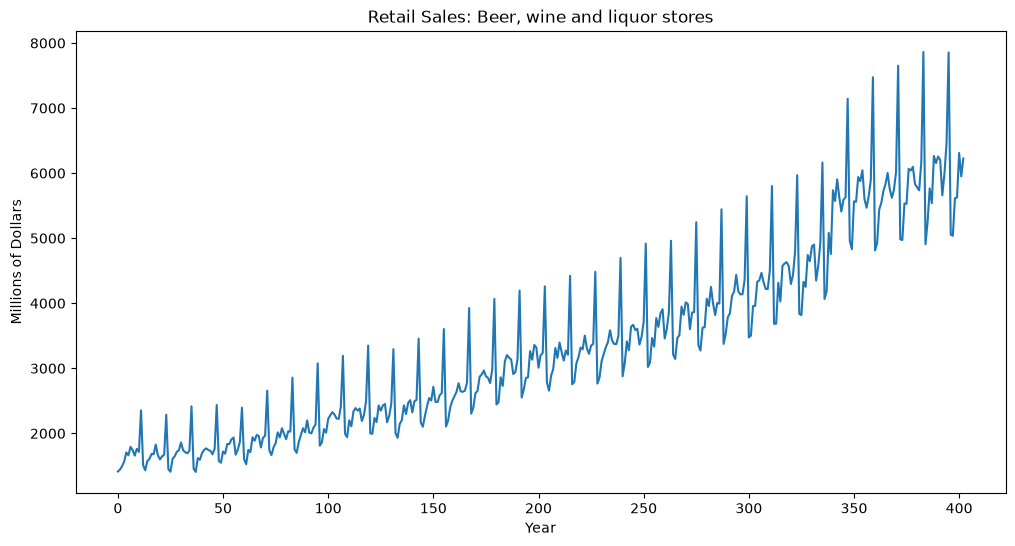

In [2]:
#The following is FRED data on retail sales (in millions of dollars) for beer, wine and liquor stores (https://fred.stlouisfed.org/series/MRTSSM4453USN)
beersales = pd.read_csv('../CSV/MRTSSM4453USN_October2025.csv')
print(beersales.head())
y = beersales['MRTSSM4453USN'].to_numpy()
plt.figure(figsize = (12, 6))
plt.plot(y)
plt.xlabel('Year')
plt.ylabel('Millions of Dollars')
plt.title('Retail Sales: Beer, wine and liquor stores')
plt.show()

AutoRegressive (AR) models are a simple way for obtaining forecasts (predictions) for future values of the time series. 

In [3]:
n = len(y)
print(n)
print(y)

403
[1414 1444 1496 1569 1707 1663 1792 1744 1658 1763 1715 2354 1512 1433
 1573 1606 1683 1679 1828 1665 1600 1647 1670 2287 1450 1410 1607 1648
 1715 1741 1858 1742 1710 1693 1731 2416 1459 1407 1619 1594 1696 1747
 1769 1745 1731 1678 1762 2437 1575 1549 1723 1687 1836 1837 1908 1936
 1672 1748 1871 2395 1605 1526 1745 1712 1940 1886 1976 1960 1783 1932
 1962 2657 1740 1665 1783 1848 2015 1938 2079 1993 1910 2033 2026 2857
 1755 1700 1867 1974 2078 2017 2200 2013 2000 2088 2140 3076 1810 1863
 2066 2011 2225 2278 2326 2288 2228 2223 2409 3192 1995 1941 2201 2110
 2337 2389 2349 2382 2191 2279 2495 3349 1999 1994 2236 2174 2429 2349
 2427 2451 2170 2267 2456 3294 2003 1931 2145 2202 2431 2297 2466 2511
 2323 2495 2514 3456 2169 2101 2270 2418 2543 2505 2716 2485 2481 2586
 2619 3604 2104 2194 2398 2501 2568 2637 2771 2645 2639 2656 2782 3925
 2303 2394 2616 2653 2870 2906 2966 2878 2852 2773 2987 4067 2445 2478
 2862 2730 3107 3203 3163 3136 2911 2942 3142 4195 2551 2677 2852 2861
 3

AR models work just like regression. The response vector and design matrix in the regression are set up as follows. 

In [21]:
p = 24 #this is the order of the autoregression
yreg = y[p:] #these are the response values in the autoregression
Xmat = np.ones((n-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y[p-j : n-j]
    Xmat = np.column_stack([Xmat, col])
print(Xmat.shape)
print(Xmat)

(379, 25)
[[1.000e+00 2.287e+03 1.670e+03 ... 1.496e+03 1.444e+03 1.414e+03]
 [1.000e+00 1.450e+03 2.287e+03 ... 1.569e+03 1.496e+03 1.444e+03]
 [1.000e+00 1.410e+03 1.450e+03 ... 1.707e+03 1.569e+03 1.496e+03]
 ...
 [1.000e+00 5.626e+03 5.613e+03 ... 6.096e+03 6.040e+03 6.067e+03]
 [1.000e+00 6.310e+03 5.626e+03 ... 5.834e+03 6.096e+03 6.040e+03]
 [1.000e+00 5.950e+03 6.310e+03 ... 5.783e+03 5.834e+03 6.096e+03]]


In [22]:
armod = sm.OLS(yreg, Xmat).fit()
print(armod.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     3084.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:00:07   Log-Likelihood:                -2274.2
No. Observations:                 379   AIC:                             4598.
Df Residuals:                     354   BIC:                             4697.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.1179     14.426      0.701      0.4

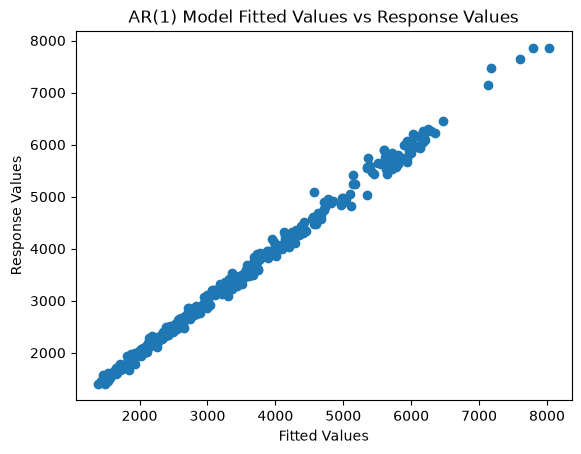

In [23]:
arfitted = armod.fittedvalues
#Plotting the fitted values against response values
plt.xlabel('Fitted Values')
plt.ylabel('Response Values')
plt.title('AR(1) Model Fitted Values vs Response Values')
plt.plot(arfitted, yreg, 'o')
plt.show()

In [24]:
#Generate k-step ahead forecasts: 
k = 100
yhat = np.concatenate([y, np.full(k, -9999)]) #extend data by k placeholder values
for i in range(1, k+1):
    ans = armod.params[0]
    for j in range(1, p+1):
        ans += armod.params[j] * yhat[n+i-j-1]
    yhat[n+i-1] = ans
predvalues = yhat[n:]

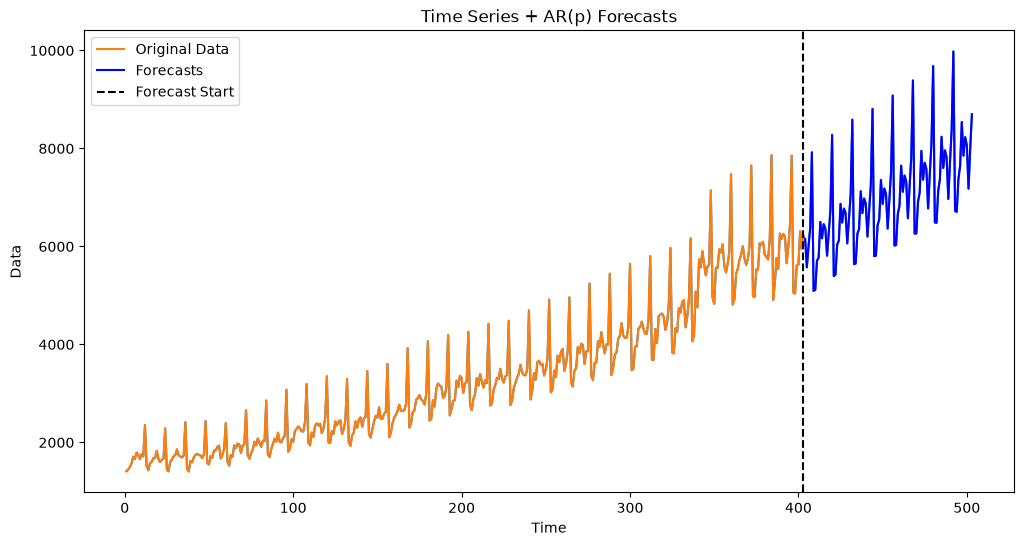

In [25]:
#Plotting the series with forecasts: 
plt.figure(figsize=(12, 6))
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat,  color='C0')
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), predvalues, label='Forecasts', color='blue')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

The predictions depend crucially on the order $p$ of the model. If $p \geq 12$, we get reasonable predictions. However for smaller values of $p$, the predictions look very unnatural. Go back and repeat the code above for other values of $p$. 

## Dataset Two: House Price Data from FRED

  observation_date  ASPUS
0       1963-01-01  19300
1       1963-04-01  19400
2       1963-07-01  19200
3       1963-10-01  19600
4       1964-01-01  19600


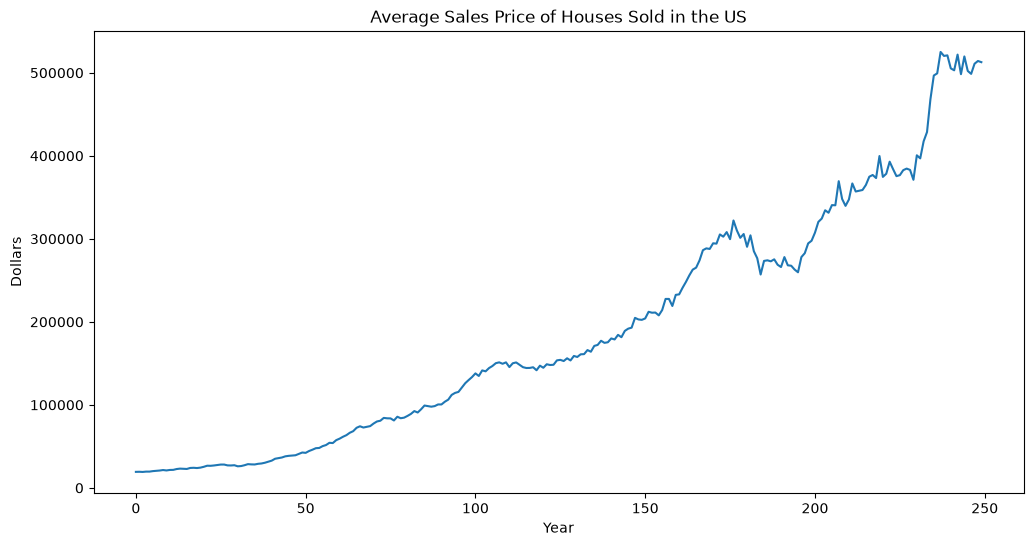

In [27]:
#The following is FRED data on Average Sales Price of Houses Sold for the US (https://fred.stlouisfed.org/series/ASPUS)
hprice = pd.read_csv('ASPUS_October2025.csv')
print(hprice.head())
y = hprice['ASPUS'].to_numpy()
plt.figure(figsize = (12, 6))
plt.plot(y)
plt.xlabel('Year')
plt.ylabel('Dollars')
plt.title('Average Sales Price of Houses Sold in the US')
plt.show()

In [28]:
p = 30 #this is the order of the AR model
n = len(y)
print(n)

250


In [29]:
yreg = y[p:] #these are the response values in the autoregression
Xmat = np.ones((n-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y[p-j : n-j].reshape(-1, 1)
    Xmat = np.column_stack([Xmat, col])
print(Xmat.shape)
print(y)

(220, 31)
[ 19300  19400  19200  19600  19600  20200  20500  20900  21500  21000
  21600  21700  22700  23200  23000  22800  24000  24200  23900  24400
  25400  26700  26600  27000  27600  28100  28100  27100  27000  27300
  26000  26300  27300  28600  28300  28200  29000  29400  30300  31600
  32800  35100  35900  36600  38000  38600  39000  39300  40900  42600
  42200  44400  46000  47800  48100  50300  51600  54300  54000  57500
  59300  61600  63500  66400  68300  72400  74200  72700  73600  74400
  77500  80000  80900  84300  83800  83700  81200  85700  83900  84600
  86700  89100  92500  90800  94700  99200  98500  97800  98500 100500
 100500 103800 106300 112000 114400 115600 120800 126100 129900 133500
 137900 134800 141500 140400 144300 146800 150200 151200 149500 151200
 145500 150100 151100 148200 145400 144400 144500 145300 141700 147200
 144700 148900 148000 148300 153600 154200 152800 156100 153500 158900
 157700 160900 161100 166000 164000 171000 172200 177200 174700 175

In [30]:
armod = sm.OLS(yreg, Xmat).fit()
print(armod.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     2885.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          4.29e-235
Time:                        19:02:13   Log-Likelihood:                -2239.4
No. Observations:                 220   AIC:                             4541.
Df Residuals:                     189   BIC:                             4646.
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1252.3043    895.312      1.399      0.1

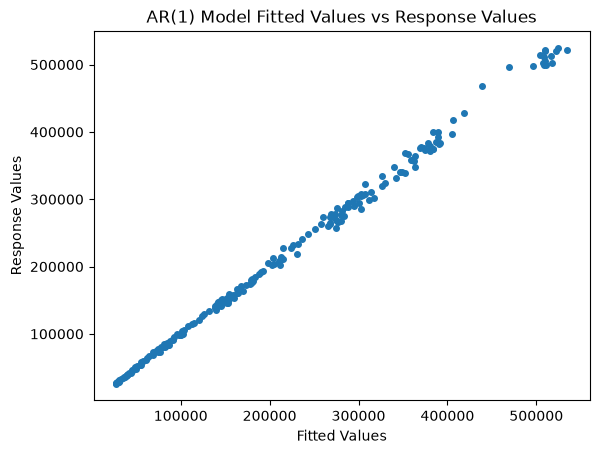

In [31]:
arfitted = armod.fittedvalues
#Plotting the fitted values against response values
plt.xlabel('Fitted Values')
plt.ylabel('Response Values')
plt.title('AR(1) Model Fitted Values vs Response Values')
#plotting with reduced size points for better visibility    
plt.plot(arfitted, yreg, 'o', markersize=4)  

plt.show()

In [32]:
#Generate k-step ahead forecasts: 
k = 100
yhat = np.concatenate([y, np.full(k, -9999)]) #extend data by k placeholder values
for i in range(1, k+1):
    ans = armod.params[0]
    for j in range(1, p+1):
        ans += armod.params[j] * yhat[n+i-j-1]
    yhat[n+i-1] = ans
predvalues = yhat[n:]

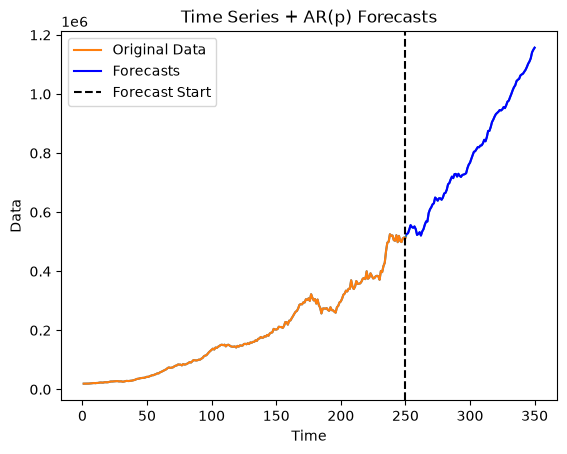

In [33]:
#Plotting the series with forecasts: 
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat, color='C0')
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), predvalues, label='Forecasts', color='blue')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

Repeat the above code for different values of $p$ to see how the predictions change. 

We will now apply AR models to logarithms of $y$. 

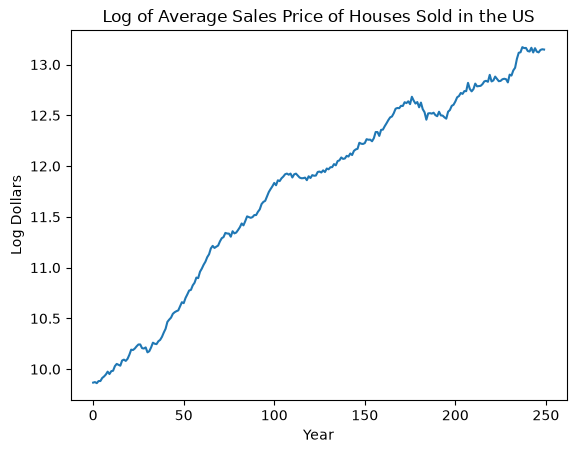

In [34]:
ylog = np.log(y)
plt.plot(ylog)
plt.xlabel('Year')
plt.ylabel('Log Dollars')
plt.title('Log of Average Sales Price of Houses Sold in the US')
plt.show()

In [35]:
p = 30 #this is the order of the AR model
n = len(ylog)
print(n)

250


In [36]:
yreg = ylog[p:] #these are the response values in the autoregression
Xmat = np.ones((n-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = ylog[p-j : n-j].reshape(-1, 1)
    Xmat = np.column_stack([Xmat, col])

In [37]:
armod_log = sm.OLS(yreg, Xmat).fit()
print(armod_log.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                     7003.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.96e-271
Time:                        19:03:28   Log-Likelihood:                 509.83
No. Observations:                 220   AIC:                            -957.7
Df Residuals:                     189   BIC:                            -852.5
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1013      0.033      3.049      0.0

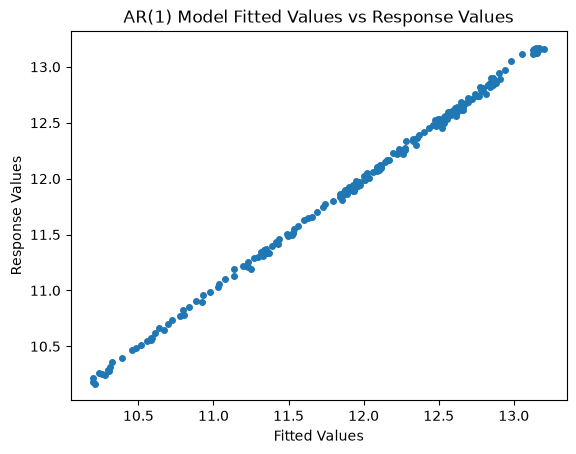

In [38]:
arfitted_log = armod_log.fittedvalues
#Plotting the fitted values against response values
plt.xlabel('Fitted Values')
plt.ylabel('Response Values')
plt.title('AR(1) Model Fitted Values vs Response Values')
#plotting with reduced size points for better visibility    
plt.plot(arfitted_log, yreg, 'o', markersize=4)  

plt.show()

In [39]:
#Generate k-step ahead forecasts: 
k = 100
yhat = np.concatenate([ylog, np.full(k, -9999)]) #extend data by k placeholder values
for i in range(1, k+1):
    ans = armod_log.params[0]
    for j in range(1, p+1):
        ans += armod_log.params[j] * yhat[n+i-j-1]
    yhat[n+i-1] = ans
predvalues_log = yhat[n:]

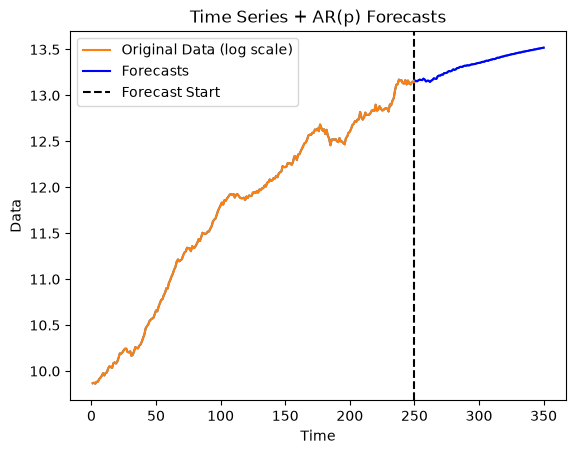

In [40]:
#Plotting the series with forecasts: 
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat, color='C0')
plt.plot(range(1, n + 1), ylog, label='Original Data (log scale)', color='C1')
plt.plot(range(n + 1, n + k + 1), predvalues_log, label='Forecasts', color='blue')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

We now plot the predictions on the original data. 

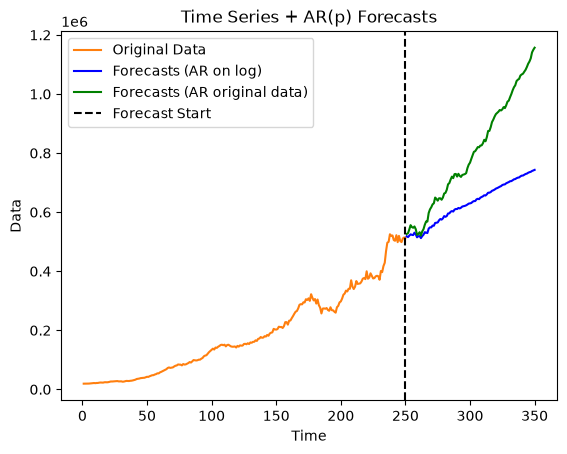

In [41]:
#Plotting the series with forecasts: 
time_all = np.arange(1, n + k + 1)
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), np.exp(predvalues_log), label='Forecasts (AR on log)', color='blue')
plt.plot(range(n + 1, n + k + 1), predvalues, label='Forecasts (AR original data)', color='green')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

## Sunspots Data

Autoregressive models were invented in the context of the sunspots data by Yule in 1927.

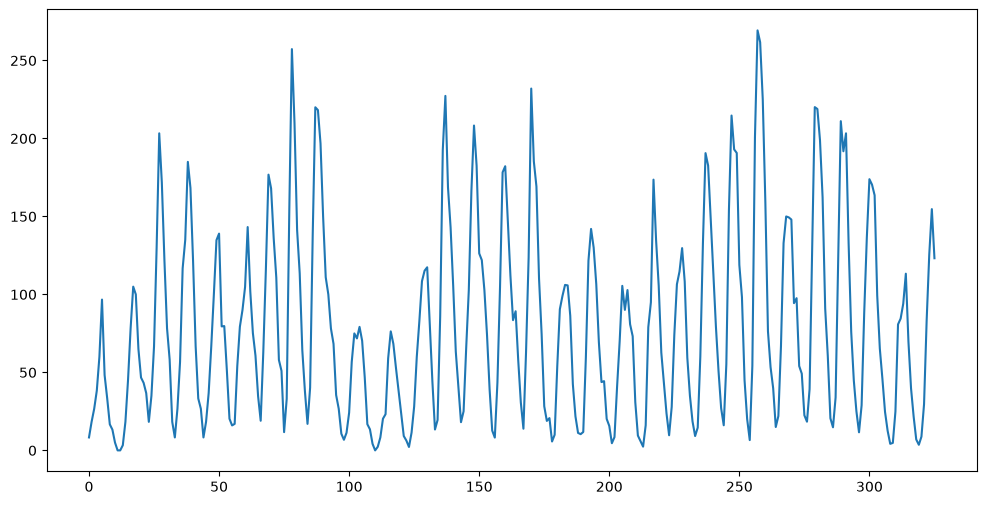

In [42]:
sunspots = pd.read_csv('../CSV/SN_y_tot_V2.0_17Sept2026.csv', header = None, sep = ';')
y = sunspots.iloc[:,1].values
n = len(y)
plt.figure(figsize = (12, 6))
plt.plot(y)
plt.show()

The most basic model for this dataset is the single sinusoid model: 
\begin{equation*}
    y_t = \beta_0 + \beta_1 \cos(2 \pi f t) + \beta_2 \sin(2 \pi f t) + \epsilon_t
\end{equation*} 
with $\epsilon_t \overset{\text{i.i.d}}{\sim} N(0, \sigma^2)$. We previously used this model. For estimating $f$, we calculate $RSS(f)$ for a bunch of $f$ values, and then minimize it over $f$. 

In [43]:
#rss function:
def rss(f):
    n = len(y)
    X = np.column_stack([np.ones(n)])
    x = np.arange(1, n+1)
    xcos = np.cos(2 * np.pi * f * x)
    xsin = np.sin(2 * np.pi * f * x)
    X = np.column_stack([X, xcos, xsin])
    md = sm.OLS(y, X).fit()
    ans = np.sum(md.resid ** 2)
    return ans

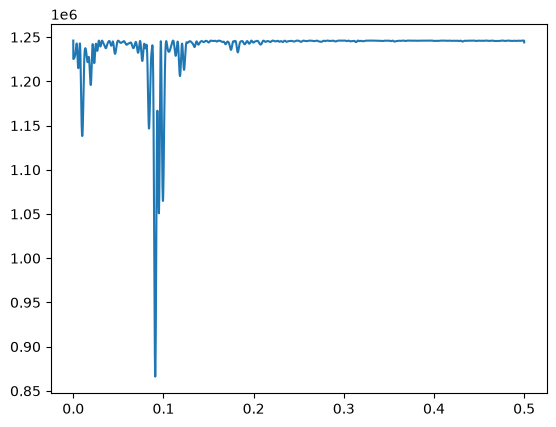

In [44]:
ngrid = 10000
fvals = np.linspace(0, 0.5, ngrid)
rssvals = np.array([rss(f) for f in fvals])
plt.plot(fvals, rssvals) #plot rss and find f which minimizes rss
plt.show()

In [46]:
fhat = fvals[np.argmin(rssvals)]
print(fhat) 
print(1/fhat)  #period corresponding to fhat

0.09090909090909091
11.0


The MLE of $f$ is basically $1/11$ (corresponding to the 11-year solar cycle). After estimating $f$, the other parameters $\beta_0, \beta_1, \beta_2, \sigma$ are estimated as in usual linear regression as follows. 

In [47]:
#Estimates of beta and sigma: 
x = np.arange(1, n+1)
f = fhat
xcos = np.cos(2 * np.pi * f * x)
xsin = np.sin(2 * np.pi * f * x)
X = np.column_stack([np.ones(n), xcos, xsin])
md = sm.OLS(y, X).fit()
print(md.params) #this gives estimates of beta_0, beta_1, beta_2 
rss_fhat = np.sum(md.resid ** 2)
#there are two estimates for sigma (which usually give similar values)
sigma_mle = np.sqrt(rss_fhat/n)
sigma_unbiased = np.sqrt((rss_fhat)/(n-3))
print(np.array([sigma_mle, sigma_unbiased])) 

[ 78.86715227 -38.27095266 -29.26525055]
[51.54476939 51.78358813]


Back in Lecture 7, we also computed an uncertainty interval (credible region) for $f$, using the following posterior formula:
\begin{align*}
  \text{posterior}(f) \propto I\{0 < f < 1/2 \} |X_f^T X_f|^{-1/2} \left(\frac{1}{RSS(f)} \right)^{(n-p)/2}
\end{align*}
with $p = 3$ (the number of columns of $X_f$). We evaluated this posterior on a fine grid of frequencies as in the code below. 

In [48]:
def logpost(f):
    x = np.arange(1, n+1)
    xcos = np.cos(2 * np.pi * f * x)
    xsin = np.sin(2 * np.pi * f * x)
    X = np.column_stack([np.ones(n), xcos, xsin])
    p = X.shape[1]
    md = sm.OLS(y, X).fit()
    rss = np.sum(md.resid ** 2)
    sgn, log_det = np.linalg.slogdet(np.dot(X.T, X)) #sgn gives the sign of the determinant (in our case, this should 1)
    #log_det gives the logarithm of the absolute value of the determinant
    logval = ((p-n)/2) * np.log(rss) - (0.5)*log_det
    return logval

allfvals = np.arange(0.01, 0.5, 0.00001) #fine grid of frequencies (staying away from 0 where the determinant term is close to zero)
logpostvals = np.array([logpost(f) for f in allfvals])
postvals = np.exp(logpostvals - np.max(logpostvals))
postvals = postvals/(np.sum(postvals))
print(allfvals[np.argmax(postvals)]) #posterior mode (same as the RSS minimizer)
print(1/allfvals[np.argmax(postvals)])

0.09088999999999671
11.00231048520229


In [50]:
#95% credible interval: smallest symmetric region (in the grid) around the posterior mode with posterior probability at least 0.95
def PostProbAroundMax(m):
    est_ind = np.argmax(postvals)
    ans = np.sum(postvals[(est_ind-m):(est_ind+m+1)])
    return(ans)
m = 0
while PostProbAroundMax(m) <= 0.95:
    m = m+1
est_ind = np.argmax(postvals)
f_est = allfvals[est_ind]
#95% credible interval for f:
ci_f_low = allfvals[est_ind - m]
ci_f_high = allfvals[est_ind + m]
print(np.array([f_est, ci_f_low, ci_f_high]))

#For the period (1/frequency):
period_est = 1/f_est
ci_period_low = 1/ci_f_high
ci_period_high = 1/ci_f_low
print(np.array([period_est, ci_period_low, ci_period_high]))
#uncertainty in days:
print(np.array([(period_est - ci_period_low)*365, (ci_period_high - period_est)*365]))

[0.09089 0.09061 0.09117]
[11.00231049 10.96852035 11.03630946]
[12.33340059 12.40962511]


As in Lecture 7, the 95% credible interval for the period is $[10.97, 11.04]$ years, i.e.,
\begin{align*}
    [11~\text{years} - 12~\text{days}, 11~\text{years} + 12~\text{days}].
\end{align*}
Note that this interval is quite narrow. 

Yule did not like the simple single sinusoidal model for the sunspots data, mainly because if we simulate data from it, the data will look much more noisy and irregular as opposed to the sunspots data which have a smooth appearance. We can check this by simulating synthetic data from the single sinusoid model and comparing the synthetic data with the actual sunspots data. We will take the parameters $f, \beta, \sigma$ to be those estimated from the sunspots dataset to make the plots  comparable to the actual sunspots data. 

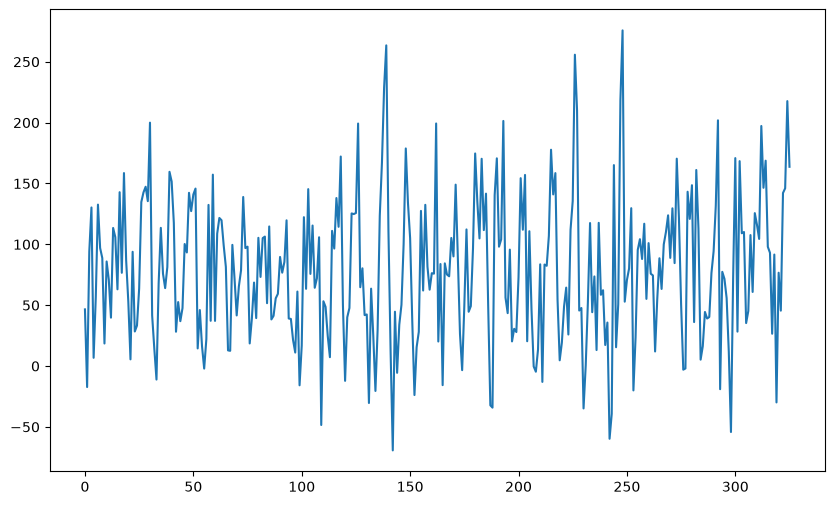

In [51]:
rng = np.random.default_rng(seed = 42)
errorsamples = rng.normal(loc = 0, scale = sigma_mle, size = n)
sim_data = md.fittedvalues + errorsamples
plt.figure(figsize = (10, 6))
plt.plot(sim_data)
plt.show()

To facilitate comparison with the actual sunspots dataset, let us plot a bunch of these simulated datasets along with the real sunspots data (just to see if the sunspots dataset can be spotted as the “odd one out” from these plots).

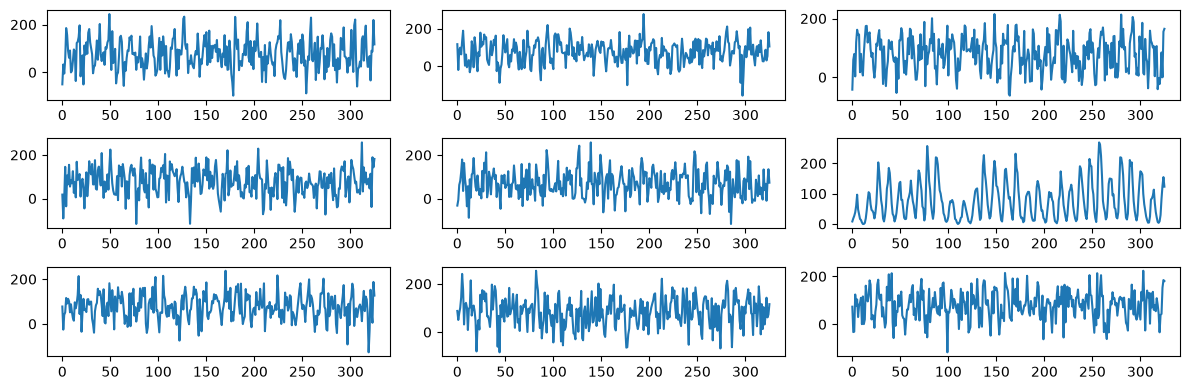

In [52]:
fig, axes = plt.subplots(3, 3, figsize = (12, 4))
axes = axes.flatten()
for i in range(5):
    errorsamples = rng.normal(loc = 0, scale = sigma_mle, size = n)
    sim_data = md.fittedvalues + errorsamples
    axes[i].plot(sim_data)
axes[5].plot(y)
for i, idx in enumerate(range(6, 9)):
    errorsamples = rng.normal(loc = 0, scale = sigma_mle, size = n)
    sim_data = md.fittedvalues + errorsamples
    axes[idx].plot(sim_data)
plt.tight_layout()
plt.show()

It is clear from the above plot-grid that the sunspots dataset sticks out as the odd one out. This shows that the simulated datasets (which are too wiggly and do not have well-defined peaks) are generated from a model that ignores many aspects of the sunspots dataset.

### Yule Model

Yule model is given by: 
\begin{equation*}
   y_t = \phi_0 + \phi_1 y_{t-1} - y_{t-2} + \epsilon_t
\end{equation*}
Note that $\phi_2$ in the usual AR(2) model is set to -1 above. Also $\phi_1$ is given by $2 \cos(2 \pi f)$. The above model can be rewritten as 
\begin{equation*}
  y_t + y_{t-2} = \phi_0 + \phi_1 y_{t-1} + \epsilon_t
\end{equation*}
so we can estimate $\phi_0$ and $\phi_1$ by regressing $y_t + y_{t-2}$ on $y_{t-1}$. 

In [53]:
p = 2
yreg = y[p:]
x1 = y[1:-1]
x2 = y[:-2]
Xmat = np.column_stack([np.ones(len(yreg)), x1])
print(Xmat.shape)

(324, 2)


In [54]:
y_adjusted = yreg + x2
yulemod = sm.OLS(y_adjusted, Xmat).fit()
print(yulemod.summary())
print(yulemod.params)
slpe_est = yulemod.params[1]

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                     4258.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.06e-187
Time:                        19:39:27   Log-Likelihood:                -1537.0
No. Observations:                 324   AIC:                             3078.
Df Residuals:                     322   BIC:                             3086.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         28.7410      2.513     11.439      0.0

From the estimate for $\phi_1$, the frequency parameter can be estimated using the relation: $\phi_1 = 2 \cos (2 \pi f)$. 

In [55]:
yulefhat = np.arccos(slpe_est/2) / (2 * np.pi)
print(1/yulefhat)

10.229784670602625


The period corresponding to this frequency is $10.259$ which is smaller than the period of 11 that we get by fitting $y_t = \beta_0 + \beta_1 \cos(2 \pi f t) + \beta_2 \sin(2 \pi f t) + \epsilon_t$. 

### Uncertainty quantification for $f$ in the Yule model

How uncertain is this estimate of the period? The Yule model is a linear regression (of $z_t = y_t + y_{t-2}$ on $y_{t-1}$ with an intercept), so we can use the Bayesian analysis of linear regression from Lecture 4. With the flat prior on $(\phi_0, \phi_1)$ and the prior $1/\sigma$ on $\sigma$, the posterior is
\begin{align*}
   \sigma^2 \mid \text{data} \sim \frac{RSS}{\chi^2_{N - p}} \qquad \text{and} \qquad (\phi_0, \phi_1) \mid \sigma, \text{data} \sim N\left(\hat{\phi}, \sigma^2 (X^T X)^{-1}\right)
\end{align*}
where $N = n - 2$ is the number of observations in the regression and $p = 2$ is the number of parameters. Integrating out $\sigma$, the marginal posterior of $\phi_1$ is a shifted and scaled $t$-distribution:
\begin{align*}
   \phi_1 \mid \text{data} \sim \hat{\phi}_1 + \hat{\sigma} \sqrt{(X^T X)^{-1}_{11}} \; t_{N-p} \qquad \text{with } \hat{\sigma}^2 = \frac{RSS}{N - p}.
\end{align*}
This gives a 95% credible interval for $\phi_1$. Since $f = \arccos(\phi_1/2)/(2 \pi)$ is a *decreasing* function of $\phi_1$ (and the period $1/f$ is an *increasing* function of $\phi_1$), the 95% credible interval for $f$ (or for the period) is obtained by simply transforming the endpoints of the interval for $\phi_1$.

In [56]:
from scipy import stats

N_yule, p_yule = Xmat.shape #N = n - 2 observations and p = 2 parameters in the Yule regression
phi1_hat = yulemod.params[1]
rss_yule = np.sum(yulemod.resid ** 2)
sigma2_hat = rss_yule/(N_yule - p_yule)
XtX_inv = np.linalg.inv(Xmat.T @ Xmat)
se_phi1 = np.sqrt(sigma2_hat * XtX_inv[1, 1]) #this is the "std err" of x1 in the regression summary above
print(np.array([phi1_hat, se_phi1]))

#95% credible interval for phi1 (shifted and scaled t distribution with N - p degrees of freedom):
tq = stats.t.ppf(0.975, N_yule - p_yule)
phi1_low = phi1_hat - tq * se_phi1
phi1_high = phi1_hat + tq * se_phi1
print(np.array([phi1_hat, phi1_low, phi1_high])) #these coincide with the 95% confidence interval in the regression summary

[1.63446369 0.02504764]
[1.63446369 1.58518601 1.68374138]


In [57]:
#f = arccos(phi1/2)/(2 pi) is decreasing in phi1, so the endpoints get swapped:
yule_f_est = np.arccos(phi1_hat/2) / (2 * np.pi)
yule_ci_f_low = np.arccos(phi1_high/2) / (2 * np.pi)
yule_ci_f_high = np.arccos(phi1_low/2) / (2 * np.pi)
print(np.array([yule_f_est, yule_ci_f_low, yule_ci_f_high])) #95% credible interval for f in the Yule model

#For the period (1/frequency), as before:
yule_period_est = 1/yule_f_est
yule_ci_period_low = 1/yule_ci_f_high
yule_ci_period_high = 1/yule_ci_f_low
print(np.array([yule_period_est, yule_ci_period_low, yule_ci_period_high]))
#uncertainty in days:
print(np.array([(yule_period_est - yule_ci_period_low)*365, (yule_ci_period_high - yule_period_est)*365]))

[0.09775377 0.09072725 0.10436529]
[10.22978467  9.58172996 11.02204688]
[236.53996816 289.17570528]


So the 95% credible interval for the period under the Yule model is $[9.58, 11.02]$ years, i.e.,
\begin{align*}
    [10.23~\text{years} - 237~\text{days}, 10.23~\text{years} + 289~\text{days}].
\end{align*}
Compare this with the interval $[10.97, 11.04]$ years ($11$ years $\pm 12$ days) from the single sinusoid model: the Yule interval is about 40 times wider, and it (just) contains 11.

Why are the two intervals so different? In the single sinusoid model, $f$ is determined by phase coherence over the whole dataset: if $f$ is slightly off, the fitted sinusoid drifts out of phase with the data over the roughly 30 cycles in the dataset, and $RSS(f)$ increases sharply. In the Yule model, $\hat{\phi}_1$ is essentially read off the *local* relation between $y_t + y_{t-2}$ and $y_{t-1}$, which is much noisier.

In [58]:
#Generate k-step ahead forecasts: 
k = 100
yhat = np.concatenate([y, np.full(k, -9999)]) #extend data by k placeholder values
for i in range(1, k+1):
    ans = yulemod.params[0] - yhat[n+i-3]
    ans += yulemod.params[1] * yhat[n+i-2]
    yhat[n+i-1] = ans
predvalues = yhat[n:]
print(predvalues)
print(yhat)

[ 75.40697305  28.79100562   0.39192621   0.59062938  29.31448189
  76.06387284 123.7502026  154.94238637 158.23854857 132.43382223
  86.96077169  38.4414478    4.61142496  -2.16319529  20.5939567
  64.56431569 113.67511911 149.97458535 160.19394164 140.59764224
  98.34884602  48.89102186  10.30280005  -3.3104234   13.02747893
  53.34441057 102.90306931 143.58796615 160.52729422 147.52911413
 109.3447326   59.93192737  17.35287269  -2.82824113   6.7655157
  42.62727674  91.64826639 135.9095332  159.23197725 153.09039853
 119.72976701  71.34460469  25.62144501  -0.72623717   1.93259253
  32.62603532  80.13452355 127.09197996 156.33374945 157.17090363
 129.29743227  82.9021011   34.94408803   2.95378798  -1.37518299
  23.53957119  68.59080332 117.31065247 151.89024501 159.68948444
 137.85746561  94.374584    45.1354115    8.13865328  -3.09203236
  15.54857792  57.24666431 106.76006238 145.98982755 160.59605641
 145.23964204 105.53391139  55.99275055  14.72525239  -3.18381428
   8.8119645

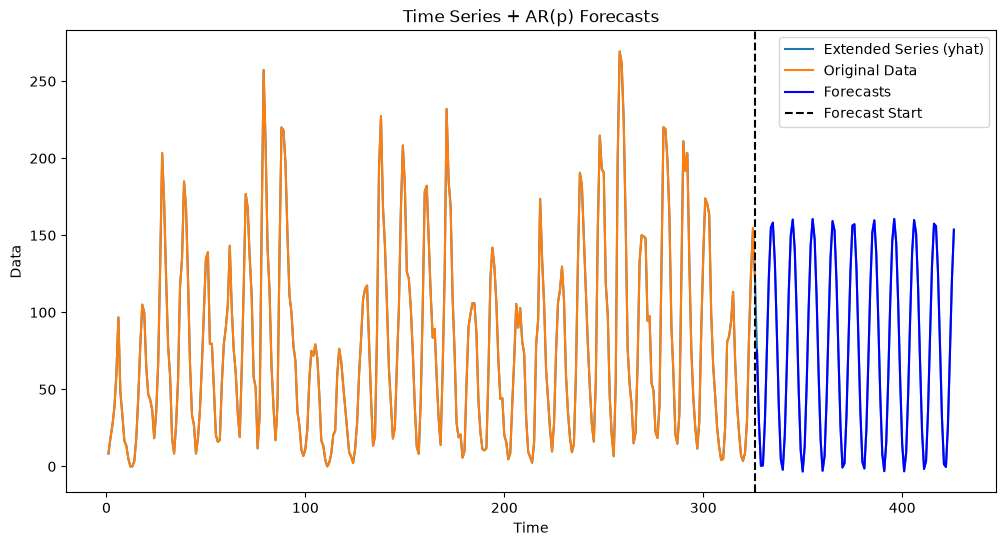

In [59]:
#Plotting the series with forecasts: 
plt.figure(figsize=(12, 6))
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat, label='Extended Series (yhat)', color='C0')
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), predvalues, label='Forecasts', color='blue')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

The predictions above are perfectly sinusoidal. Because the cycles for the sunspots data are irregular and can have different periods, there is a danger that these perfectly sinusoidal predictions can get out of phase sometimes leading to loss of prediction accuracy. 

Below, we simulate datasets using the Yule model. 

27.796017406459733


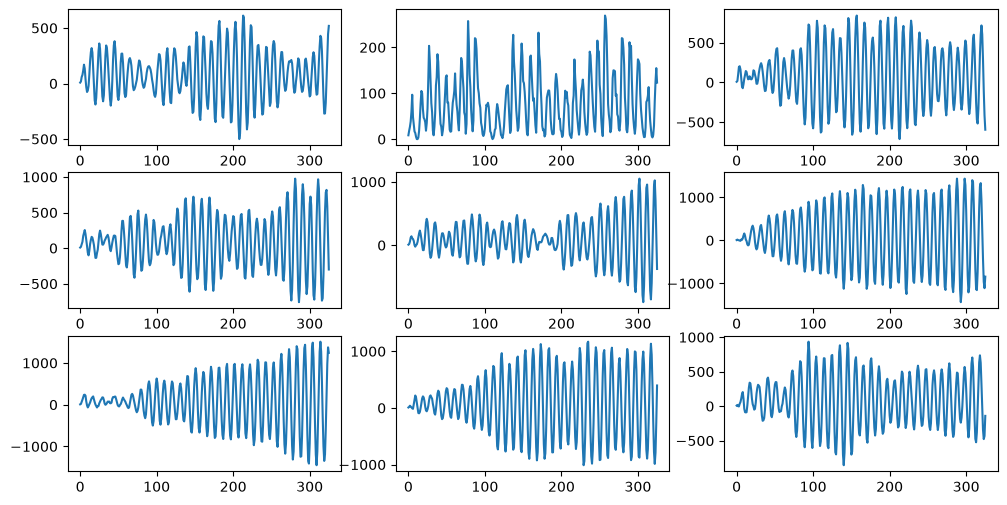

In [60]:
#Simulating from the Yule Model:
rng = np.random.default_rng(seed = 42)
sighat = np.sqrt(np.mean(yulemod.resid ** 2))
print(sighat)
fig, axes = plt.subplots(3, 3, figsize = (12, 6))
axes = axes.flatten()
for j in range(1):
    ysim = y.copy()
    for i in range(2, n):
        err = rng.normal(loc = 0, scale = sighat, size = 1)
        ysim[i] = yulemod.params[0] + yulemod.params[1] * ysim[i-1] - ysim[i-2] + err[0]
    axes[j].plot(ysim)
axes[1].plot(y)    
for j in range(2, 9):
    ysim = y.copy()
    for i in range(2, n):
        err = rng.normal(loc = 0, scale = sighat, size = 1)
        ysim[i] = yulemod.params[0] + yulemod.params[1] * ysim[i-1] - ysim[i-2] + err[0]
    axes[j].plot(ysim)
plt.show()

The sunspots dataset still probably sticks out compared to the synthetic datasets. However, all these synthetic datasets are quite smooth just like the actual sunspots data. This plots shows that the two "sinusoid + noise" models described in  lecture are fundamentally different.

## AR(2) Model

The Yule model is a special case of the AR(2) model. Specifically, the AR(2) model is: $y_t = \phi_0 + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \epsilon_t$ and the Yule model is a special case obtained by taking $\phi_2 = 1$. Below we fit the AR(2) model to the sunspots data (i.e., we estimate all the parameters $\phi_0, \phi_1, \phi_2$). 

In [61]:
p = 2 #this is the order of the AR model
n = len(y)
print(n)

326


In [62]:
yreg = y[p:] #these are the response values in the autoregression
Xmat = np.ones((n-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y[p-j : n-j].reshape(-1, 1)
    Xmat = np.column_stack([Xmat, col])

In [63]:
armod = sm.OLS(yreg, Xmat).fit()
print(armod.params)
print(armod.summary())
sighat = np.sqrt(np.mean(armod.resid ** 2))
print(sighat)

[24.49130086  1.38543496 -0.69541909]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.828
Model:                            OLS   Adj. R-squared:                  0.827
Method:                 Least Squares   F-statistic:                     775.0
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.34e-123
Time:                        19:44:10   Log-Likelihood:                -1510.3
No. Observations:                 324   AIC:                             3027.
Df Residuals:                     321   BIC:                             3038.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

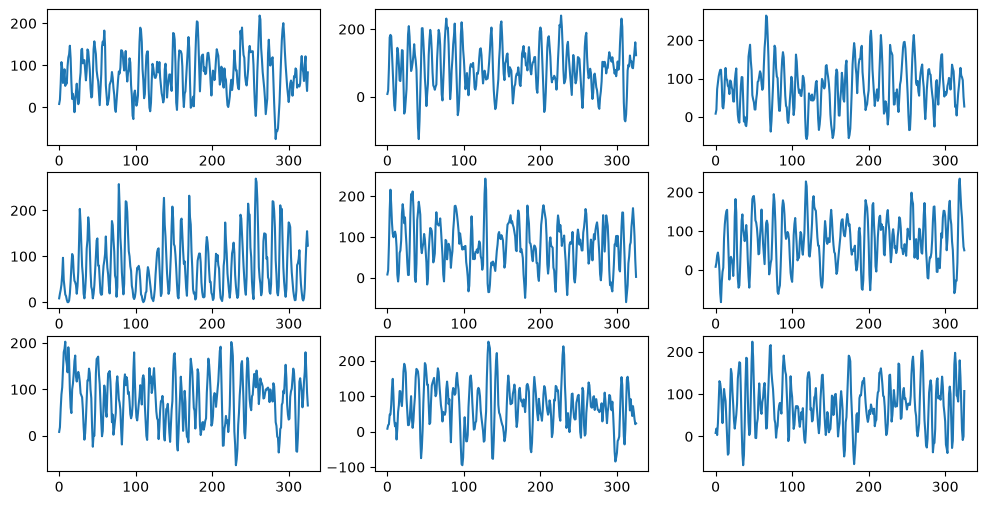

In [64]:
#Simulations from the fitted AR(2) model:
fig, axes = plt.subplots(3, 3, figsize = (12, 6))
axes = axes.flatten()

for j in range(3):
    ysim = y.copy()
    for i in range(2, n):
        err = rng.normal(loc = 0, scale = sighat, size = 1)
        ysim[i] = armod.params[0] + armod.params[1] * ysim[i-1] + armod.params[2] * ysim[i-2] + err[0]
    axes[j].plot(ysim)

axes[3].plot(y)

for j in range(4, 9):
    ysim = y.copy()
    for i in range(2, n):
        err = rng.normal(loc = 0, scale = sighat, size = 1)
        ysim[i] = armod.params[0] + armod.params[1] * ysim[i-1] + armod.params[2] * ysim[i-2] + err[0]
    axes[j].plot(ysim)
plt.show()

These datasets are still smooth (much smoother than observations simulated from $y_t = \beta_0 + \beta_1 \cos(2 \pi f t) + \beta_2 \sin(2 \pi f t) + \epsilon_t$). 

Below, we obtain predictions using the AR(2) model. 

In [65]:
#Generate k-step ahead forecasts: 
k = 100
yhat = np.concatenate([y, np.full(k, -9999)]) #extend data by k placeholder values
for i in range(1, k+1):
    ans = armod.params[0]
    for j in range(1, p+1):
        ans += armod.params[j] * yhat[n+i-j-1]
    yhat[n+i-1] = ans
predvalues = yhat[n:]


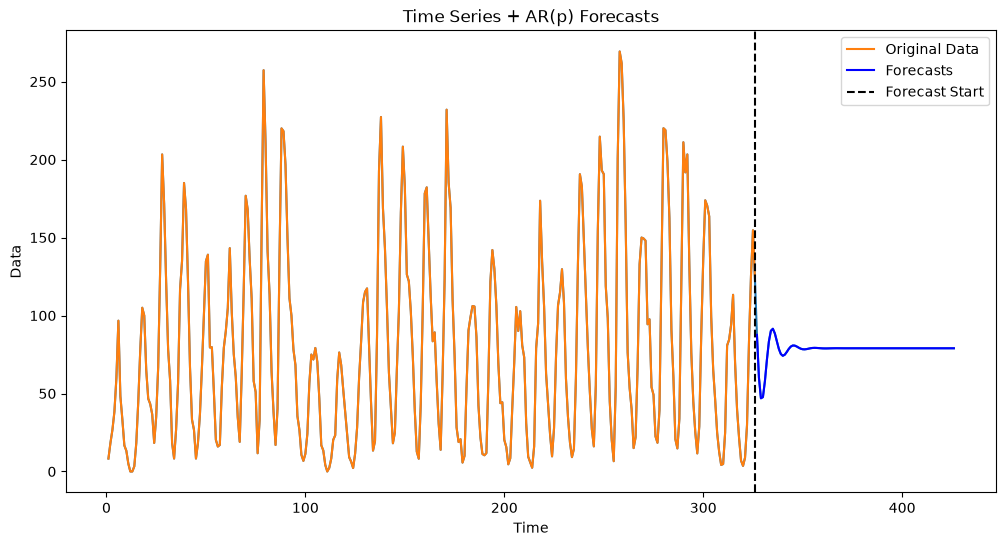

In [66]:
#Plotting the series with forecasts: 
plt.figure(figsize=(12, 6))
time_all = np.arange(1, n + k + 1)
plt.plot(time_all, yhat, color='C0')
plt.plot(range(1, n + 1), y, label='Original Data', color='C1')
plt.plot(range(n + 1, n + k + 1), predvalues, label='Forecasts', color='blue')
plt.axvline(x=n, color='black', linestyle='--', label='Forecast Start')
#plt.axhline(y=np.mean(y), color='gray', linestyle=':', label='Mean of Original Data')
plt.xlabel('Time')
plt.ylabel('Data')
plt.title('Time Series + AR(p) Forecasts')
plt.legend()
plt.show()

The predictions above are quite different from those obtained from the Yule model. The predictions actually are given by a damped sinusoid (as we shall see in the coming lectures). The predictions become flat after a few time points. When the cycles become irregular with varying periods, constant predictors might do well compared to sinusoidal predictors which may go out of phase at some places. 

Here are all the three predictions in one plot. 

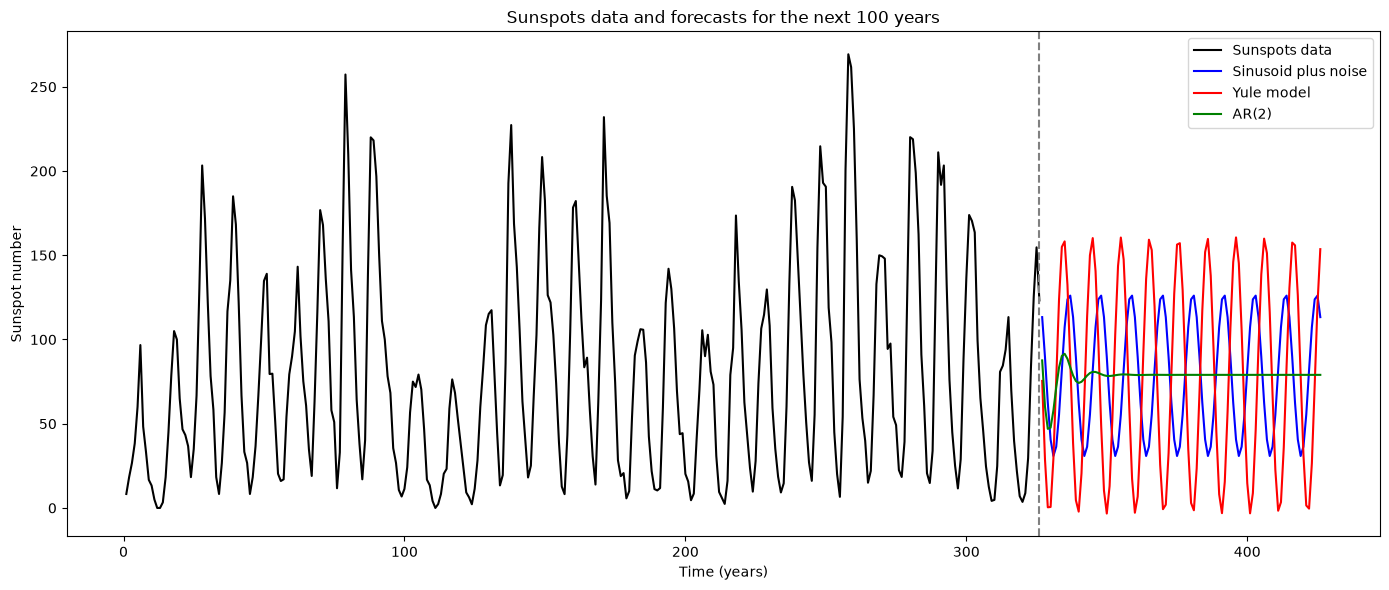

In [67]:
k = 100
future_t = np.arange(n + 1, n + k + 1)

# Sinusoid plus noise: predict the fitted mean.
pred_sinusoid = (md.params[0]
                 + md.params[1] * np.cos(2 * np.pi * fhat * future_t)
                 + md.params[2] * np.sin(2 * np.pi * fhat * future_t))

# Yule and AR(2): predict recursively, setting future errors to zero.
pred_yule = np.concatenate([y, np.zeros(k)])
pred_ar2 = np.concatenate([y, np.zeros(k)])
for t in range(n, n + k):
    pred_yule[t] = yulemod.params[0] + yulemod.params[1] * pred_yule[t-1] - pred_yule[t-2]
    pred_ar2[t] = armod.params[0] + armod.params[1] * pred_ar2[t-1] + armod.params[2] * pred_ar2[t-2]

plt.figure(figsize=(14, 6))
plt.plot(np.arange(1, n + 1), y, color='black', label='Sunspots data')
plt.plot(future_t, pred_sinusoid, color='blue', label='Sinusoid plus noise')
plt.plot(future_t, pred_yule[n:], color='red', label='Yule model')
plt.plot(future_t, pred_ar2[n:], color='green', label='AR(2)')
plt.axvline(n, color='gray', linestyle='--')
plt.xlabel('Time (years)')
plt.ylabel('Sunspot number')
plt.title('Sunspots data and forecasts for the next 100 years')
plt.legend()
plt.tight_layout()
plt.show()


### CPI Data

We can obtain the same distinction (of placing the noise in two different places) in other contexts as well. Below, we illustrate this phenomenon in the context of a linear trend model. We will look at the example of CPI data. 

We shall use the Consumer Price Index (CPI) Data (downloaded from https://fred.stlouisfed.org/series/CPIAUCSL). Changes in the CPI are used to measure Inflation. 

In [83]:
## Inflation (Consumer Price Index)
cpi = pd.read_csv('CPIAUCSL_01September2025.csv')
print(cpi)

    observation_date  CPIAUCSL
0         1947-01-01    21.480
1         1947-02-01    21.620
2         1947-03-01    22.000
3         1947-04-01    22.000
4         1947-05-01    21.950
..               ...       ...
938       2025-03-01   319.615
939       2025-04-01   320.321
940       2025-05-01   320.580
941       2025-06-01   321.500
942       2025-07-01   322.132

[943 rows x 2 columns]


In [70]:
cpi['observation_date'] = pd.to_datetime(cpi['observation_date'])
cpi.set_index('observation_date', inplace = True)
print(cpi)

                  CPIAUCSL
observation_date          
1947-01-01          21.480
1947-02-01          21.620
1947-03-01          22.000
1947-04-01          22.000
1947-05-01          21.950
...                    ...
2025-03-01         319.615
2025-04-01         320.321
2025-05-01         320.580
2025-06-01         321.500
2025-07-01         322.132

[943 rows x 1 columns]


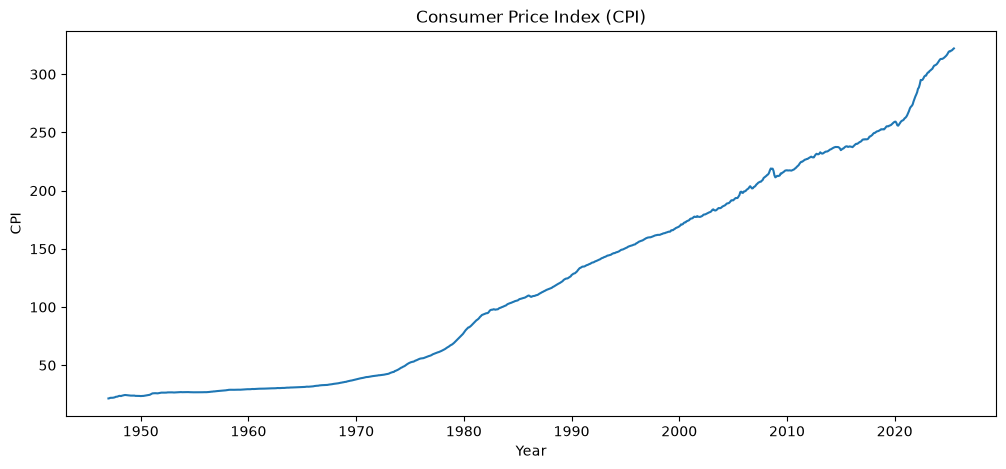

In [71]:
plt.figure(figsize=(12,5))
plt.plot(cpi.index, cpi['CPIAUCSL'], label='CPI')
plt.xlabel('Year')
plt.ylabel('CPI')
plt.title('Consumer Price Index (CPI)')
plt.show()

First, consider fitting a linear trend to the CPI data. This is given by
\begin{equation*}
  y_i = \beta_0 + \beta_1 x_i + \epsilon_i
\end{equation*}
where $y_i$ denotes the CPI for time index $i$, and $x_i = i$. The interpretation of $\beta_1$ is that it represents the numerical change in CPI for one month to the next. This is not a good model for CPI, because the relationship between CPI and data does not appear to be linear. Also CPI increases are usually reported in percentages (e.g., inflation is now at 2.8% etc.), and not in raw numerical increase. A better linear regression model here would use $y_i$ as the **logarithm** of CPI for time index $i$: 
\begin{equation*}
  y_i = \log(\text{CPI}_i) = \beta_0 + \beta_1 x_i + \epsilon_i
\end{equation*}
where $x_i = i$ as before. Now the interpretation of $\beta_1$ is that it represents the numerical change in $\log \text{CPI}_i$ for one month to the next. Note that
\begin{equation*}
   \log \text{CPI}_i - \log \text{CPI}_{i-1} = \log \frac{\text{CPI}_i}{\text{CPI}_{i-1}} \approx \frac{\text{CPI}_i}{\text{CPI}_{i-1}}  - 1 = \frac{\text{CPI}_i - \text{CPI}_{i-1}}{\text{CPI}_{i-1}} 
\end{equation*}
In other words, $100 \times \beta_1$ represents the **percent change** in CPI from one month to the next. If we want the percent change for one year (as opposed to one month), we can look at $12 \times 100 \times \beta_1$. This number can be taken to represent an estimate of the historical inflation rate. 

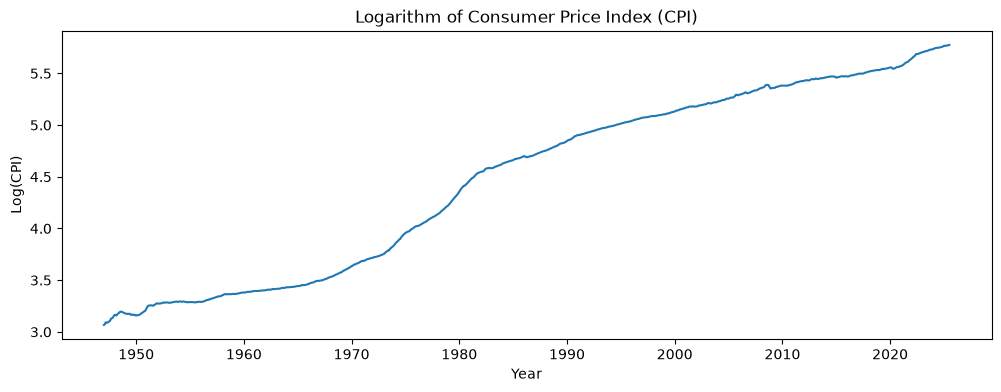

In [72]:
plt.figure(figsize=(12,4))
plt.plot(cpi.index, np.log(cpi['CPIAUCSL']), label='Logarithm of CPI')
plt.xlabel('Year')
plt.ylabel('Log(CPI)')
plt.title('Logarithm of Consumer Price Index (CPI)')
plt.show()

This model can be fit using the code below. 

In [75]:
yvec = np.log(np.array(cpi['CPIAUCSL']))
n = cpi.shape[0]
xvec = np.arange(1, n+1)
X = sm.add_constant(xvec)
linreg = sm.OLS(yvec, X).fit()
print(linreg.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.966
Method:                 Least Squares   F-statistic:                 2.695e+04
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:55:28   Log-Likelihood:                 385.22
No. Observations:                 943   AIC:                            -766.4
Df Residuals:                     941   BIC:                            -756.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9859      0.010    284.536      0.0

From this table, we see that the estimate of $\beta_0$ is 2.9859 and the estimate of $\beta_1$ is 0.0032. As per our interpretation, the month-to-month inflation rate is $100 \times \beta_1$ which is $0.32 \%$. If we want the annual inflation rate, we would have to multiply this by 12 which gives:

In [76]:
historical_inflation_rate = 12 * 100 * linreg.params[1]
print(f'Historical annual inflation rate: {historical_inflation_rate:.3f}%')

Historical annual inflation rate: 3.794%


The regression output also gives an indication of the uncertainty associated with this inflation estimate: 

In [77]:
conf_intervals_linreg = linreg.conf_int(alpha=0.05)
print(conf_intervals_linreg)
print(f'95% confidence interval for historical annual inflation rate (Linear Regression model): [{12*100*conf_intervals_linreg[1,0]:.3f}%, {   12*100*conf_intervals_linreg[1,1]:.3f}%]')

[[2.96527443 3.00646247]
 [0.003124   0.00319959]]
95% confidence interval for historical annual inflation rate (Linear Regression model): [3.749%, 3.840%]


This interval [3.749%, 3.84%] is extremely narrow for the historical inflation rate. 

Below we plot the observed data along with the fitted values. 

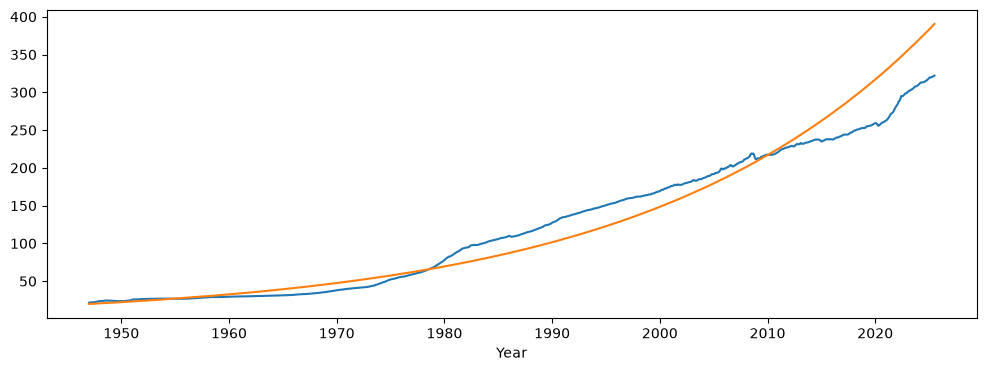

In [78]:
plt.figure(figsize=(12,4))
plt.plot(cpi.index, cpi['CPIAUCSL'], label='CPI')
plt.xlabel('Year')
plt.plot(cpi.index, np.exp(linreg.fittedvalues))
plt.show()

From this plot, it is clear that this regression model may not do a good job in predicting the values of CPI for the next few months. Below, we plot data vs fitted values on the logarithmic scale. 

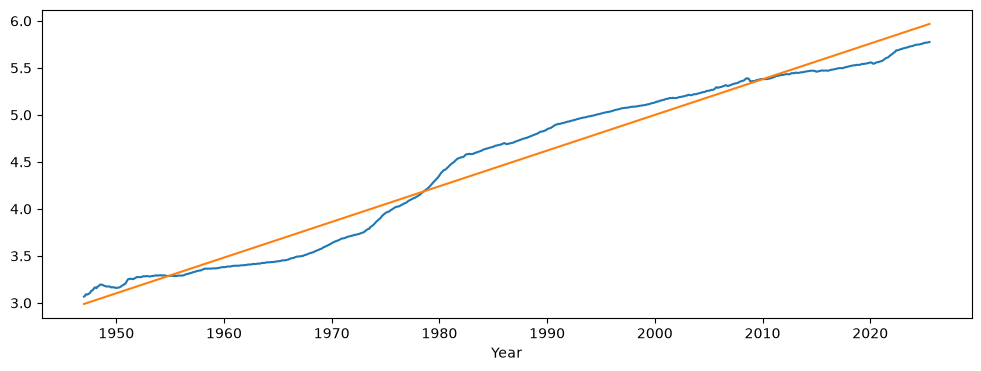

In [79]:
plt.figure(figsize=(12,4))
plt.plot(cpi.index, np.log(cpi['CPIAUCSL']), label='Logarithm of CPI')
plt.xlabel('Year')
plt.plot(cpi.index, linreg.fittedvalues)
plt.show()

Now, we shall formulate an alternative model resulting from placing the noise term in the evolution of the linear trend function, similar to how the Yule model was obtained from the sinusoid plus noise model. 

The linear trend model can be written as: 
\begin{align*}
   \log \text{CPI}_t = \ell(t) + \epsilon_t
\end{align*}
where $\ell(t) = \beta_0 + \beta_1 t$. Clearly $\ell(t) - \ell(t-1) = \beta_1$ (this is the discrete analogue of $\ell'(t) = \beta_1$). So an alternative linear plus noise model can be obtained by writing: 
\begin{align*}
   \log \text{CPI}_t - \log \text{CPI}_{t-1} = \beta_1 + \epsilon_t. 
\end{align*}
This model is the same as: 
\begin{align*}
   \log \text{CPI}_t - \log \text{CPI}_{t-1} \overset{\text{i.i.d}}{\sim} N(\beta_1, \sigma^2). 
\end{align*}
Thus, in this model, the estimate of $\beta_1$ is simply the mean of the values of $\log \text{CPI}_t - \log \text{CPI}_{t-1}$. Below we compute the estimate of $\beta_1$ as well as the usual 95% confidence interval, compare this with the estimates and intervals for the historical inflation rate obtained via the previous model, and then argue that this is a better model than the previous one. 


In [81]:
from scipy import stats

# Mean monthly log change and its usual 95% t interval.
dy = np.diff(yvec)
beta1_hat = np.mean(dy)
ci = stats.t.interval(0.95, len(dy) - 1, loc=beta1_hat, scale=stats.sem(dy))

comparison = pd.DataFrame({
    'Estimate (%)': [historical_inflation_rate, 1200 * beta1_hat],
    '95% lower (%)': [1200 * conf_intervals_linreg[1, 0], 1200 * ci[0]],
    '95% upper (%)': [1200 * conf_intervals_linreg[1, 1], 1200 * ci[1]]
}, index=['Log CPI vs time', 'Monthly log changes'])
comparison.round(3)


,Estimate (%),95% lower (%),95% upper (%)
Log CPI vs time,3.794,3.749,3.84
Monthly log changes,3.449,3.188,3.71


The estimate of $\beta_1$ here is somewhat smaller than the estimate of $\beta_1$ obtained from fitting linear regression (of $\log CPI_t$ on $t$). The confidence interval is also much more wider (about six times). 

Below we plot the residuals in both the above models. 

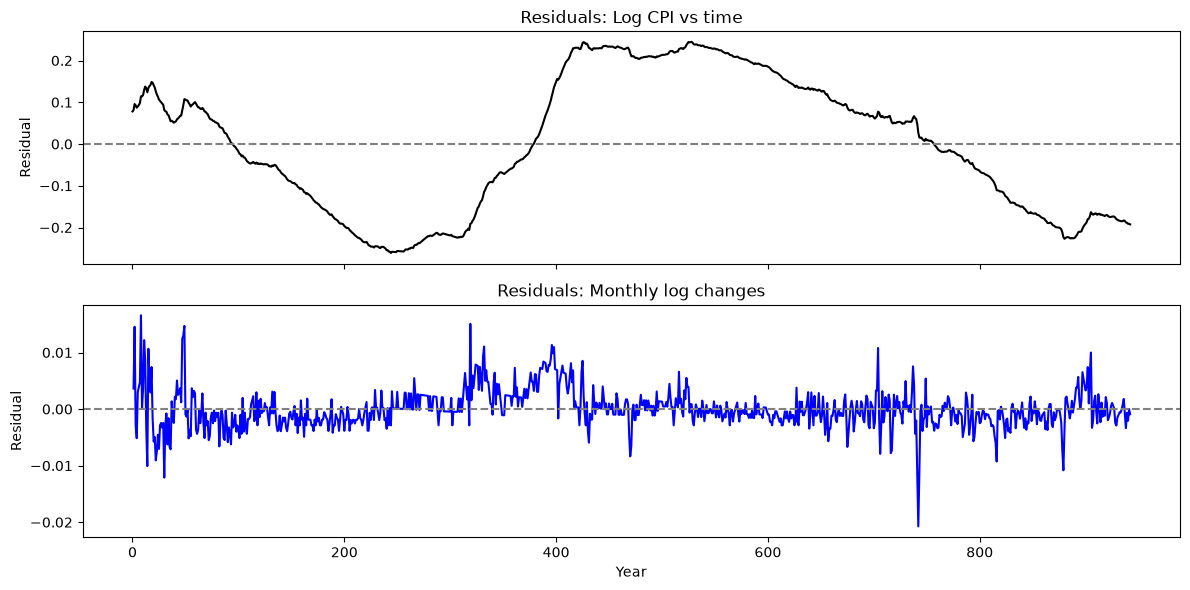

In [84]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(cpi.index, linreg.resid, color='black')
axes[0].set_title('Residuals: Log CPI vs time')

axes[1].plot(cpi.index[1:], dy - beta1_hat, color='blue')
axes[1].set_title('Residuals: Monthly log changes')

for ax in axes:
    ax.axhline(0, color='gray', linestyle='--')
    ax.set_ylabel('Residual')

axes[1].set_xlabel('Year')
plt.tight_layout()
plt.show()

From the first plot above, it is clear that $\log CPI_t = \ell(t) + \epsilon_t$ is not a good model for this dataset. In the second residual plot, there is some structure in the residuals but this suggests $\log CPI_t - \log CPI_{t-1} = \beta_1 + \epsilon_t$ is a much better model than the first one. Further improvements can be obtained by using AR models for $\log CPI_t - \log CPI_{t-1}$ as we shall see later. 